# 04 · SEO: Which Changes Can an Agent Make Alone? Reversibility, and Owner Rules That Travel Across Projects

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/04_seo_reversibility_rule_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** the SEO agent owns the search and AI visibility of three of my sites (buenavyda.com for GrabGo and Equilibra, and tepeyacrosarios.com). It writes strategies, edits a staging copy, and proposes production changes; I approve. When I correct it on one site ("don't use that phrase", "never claim to be official"), the question is whether it applies the correction to the other sites by itself, and whether it can tell a rule that is mine everywhere from a rule that belongs to one brand.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


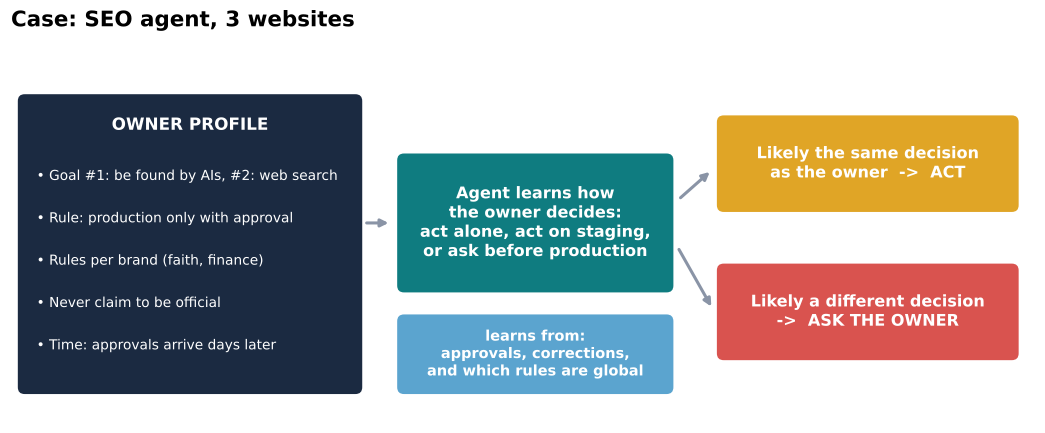

In [2]:
thesis_card("SEO agent, 3 websites",
            ["Goal #1: be found by AIs, #2: web search", "Rule: production only with approval",
             "Rules per brand (faith, finance)", "Never claim to be official",
             "Time: approvals arrive days later"],
            "act alone, act on staging,\nor ask before production",
            "approvals, corrections,\nand which rules are global")

## 1. Real data: the SEO agent's own log (4–10 Nov 2026)

Every line of the agent's log was classified by the kind of change and what happened to it. The table is the full log of its first week.


In [3]:
import numpy as np
import pandas as pd

import io
DATA = {
    "seo_agent_decision_log.csv": """date,project,kind,status,owner_correction
2026-11-10,grabgo,internal document or audit,done by agent,0
2026-11-09,tepeyac,production site change,approved by owner,0
2026-11-09,tepeyac,staging change,waiting for owner,1
2026-11-09,tepeyac,production site change,waiting for owner,0
2026-11-09,tepeyac,staging change,done by agent,1
2026-11-09,tepeyac,production site change,waiting for owner,0
2026-11-09,tepeyac,internal document or audit,approved by owner,0
2026-11-08,tepeyac,internal document or audit,waiting for owner,0
2026-11-08,tepeyac,internal document or audit,done by agent,0
2026-11-05,all,staging change,waiting for owner,0
2026-11-05,all,site code or config,done by agent,0
2026-11-05,all,site code or config,done by agent,1
2026-11-05,home + grabgo,staging change,waiting for owner,0
2026-11-05,all,internal document or audit,done by agent,1
2026-11-05,all,staging change,done by agent,0
2026-11-04,grabgo,internal document or audit,waiting for owner,0
2026-11-04,grabgo,site code or config,waiting for owner,0
2026-11-04,home + grabgo,site code or config,done by agent,0
2026-11-04,all,site code or config,waiting for owner,0
2026-11-04,all,site code or config,approved by owner,0
2026-11-04,all,internal document or audit,done by agent,0
2026-11-04,all,internal document or audit,done by agent,0
2026-11-04,all,internal document or audit,done by agent,0
2026-11-04,all,internal document or audit,done by agent,0
""",
}
def load(name):
    """The data travels inside the notebook, so it runs anywhere (Colab, Drive, GitHub)."""
    return pd.read_csv(io.StringIO(DATA[name]))

log = load("seo_agent_decision_log.csv")
pd.crosstab(log.kind, log.status, margins=True, margins_name="total")

status,approved by owner,done by agent,waiting for owner,total
kind,,,,
internal document or audit,1,7,2,10
production site change,1,0,2,3
site code or config,1,3,2,6
staging change,0,2,3,5
total,3,12,9,24


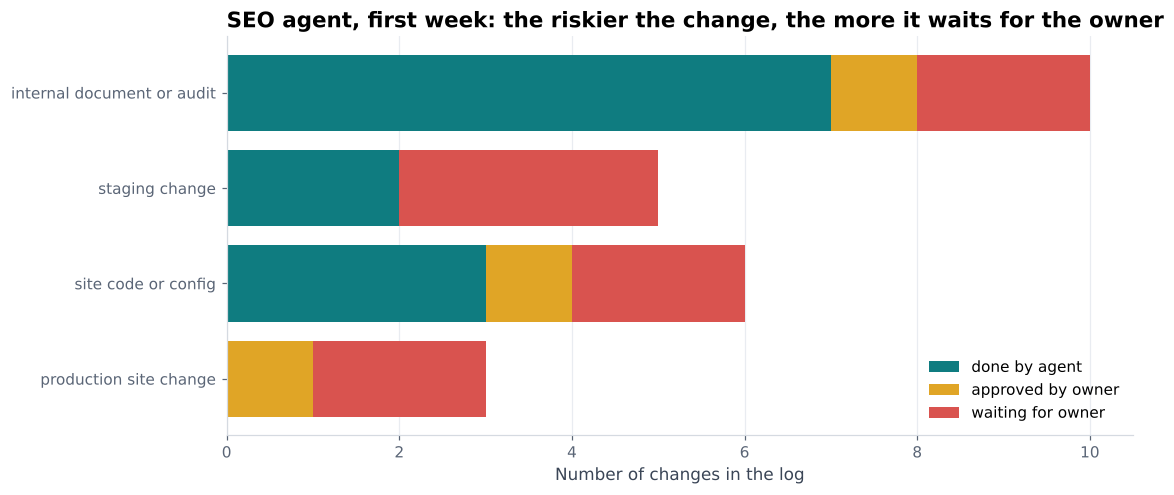

38% of the logged changes ended the week waiting for the owner; 4 lines record an owner correction or rule.


In [4]:
order = ["internal document or audit", "staging change", "site code or config", "production site change"]
ct = pd.crosstab(log.kind, log.status).reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(10.5, 4.6))
left = np.zeros(len(ct))
for col, c in [("done by agent", PALETTE["teal"]), ("approved by owner", PALETTE["gold"]), ("waiting for owner", PALETTE["coral"])]:
    v = ct[col].values if col in ct else np.zeros(len(ct))
    ax.barh(ct.index, v, left=left, color=c, label=col); left += v
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("SEO agent, first week: the riskier the change, the more it waits for the owner")
ax.set_xlabel("Number of changes in the log"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"{(log.status == 'waiting for owner').mean():.0%} of the logged changes ended the week waiting for the owner; "
      f"{log.owner_correction.sum()} lines record an owner correction or rule.")

Two of the corrections are rules that matter for the thesis: on Tepeyac I asked the agent not to use the phrase *«¿No estoy yo aquí, que soy tu madre?»*, and to remove the disclaimer that the site is not the official Basílica site while never claiming to be official. The first is a **brand rule** (it does not apply to a finance site); the second contains a **global rule** (never claim to be official, on any site). An agent that cannot tell them apart either forgets the rule on the next site or applies it where it does not belong.

## 2. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| Concrete problems in AI safety [1] | Avoiding negative side effects and safe exploration are core problems for agents that act in the world | Production changes are side effects the owner cannot easily undo |
| Side effects and reversibility [2] | Penalizing actions that reduce the reachability of states (irreversibility) yields agents that avoid unrecoverable changes | Reversibility is a principled axis for granting autonomy |
| Written principles applied broadly (Constitutional AI) [3] | A short list of natural-language principles can steer a model's behaviour across many situations | An owner's correction can become a principle reused everywhere |
| Generative Engine Optimization [4] | Specific content strategies raise visibility in generative engines by up to 40%, keyword stuffing does not help, and what works varies by domain | The owner's goal (be found by AIs) is domain-specific, so priorities differ per site |
| Learning to defer [5] | Learn when to pass the decision to the expert | Asking is a decision with a cost, not a default |

**Gap.** Safety research treats reversibility in physical environments; personalization research treats preferences one task at a time. The thesis needs both: **which actions** an agent may take alone, and **how far** an owner's correction should travel.


## 3. Experiment: four agents over 12 weeks and three sites

Each week the agent produces 30 changes spread over the three sites, of four kinds (internal document, staging change, site code or config, production change). The owner has **3 global rules** (true on every site) and **2 brand rules** (true on one site only). Each change may touch a rule. The owner rejects any change that breaks a rule that applies to that site, and answers questions once a week (a question waits 3.5 days on average).

1. **Ask for everything** (how the agent started).
2. **Autonomy by reversibility**: acts alone on internal documents and staging; asks before code and production.
3. **Reversibility + rules learned per site**: when corrected, the agent remembers the rule *for that site only*.
4. **Reversibility + rules that travel**: when corrected, the agent asks once "does this apply to all sites?" and stores the rule as global or brand-specific.

**Error** = a change the agent made that the owner would have rejected. **Re-specification** = the owner has to state a rule he already stated.


In [5]:
SITES = ["buenavyda", "grabgo", "tepeyac"]
KINDS = {"internal document": 0.35, "staging change": 0.30, "site code or config": 0.15, "production change": 0.20}
REVERSIBLE = {"internal document", "staging change"}
RULES = {"G1": "all", "G2": "all", "G3": "all", "B_tepeyac_phrase": "tepeyac", "B_finance_disclaimer": "buenavyda"}

def applies(rule, site): return RULES[rule] == "all" or RULES[rule] == site

def week_changes(rng, n=30):
    for _ in range(n):
        site = SITES[rng.integers(3)]; kind = rng.choice(list(KINDS), p=list(KINDS.values()))
        touched = [r for r in RULES if rng.random() < 0.06]          # rules this change could break
        yield site, kind, touched

def run(policy, weeks=12, seed=0):
    rng = np.random.default_rng(seed)
    known = {}                     # rule -> "all" | set of sites it is known for
    stated = {r: 0 for r in RULES} # how many times the owner had to state each rule
    q = err = act = 0; delay = []
    for w in range(weeks):
        for site, kind, touched in week_changes(rng):
            breaks = [r for r in touched if applies(r, site)]
            blocks = [r for r in touched if r in known and (known[r] == "all" or site in known[r])]
            if blocks and policy != "ask everything":
                act += 1; continue                         # agent avoids the change by itself
            ask = policy == "ask everything" or kind not in REVERSIBLE
            if ask:
                q += 1; delay.append(rng.uniform(0, 7))
                for r in breaks:                           # the owner rejects and explains the rule
                    stated[r] += 1
                    if policy == "rules travel":
                        known[r] = "all" if RULES[r] == "all" else known.get(r, set()) | {site}
                    elif policy == "rules per site":
                        known[r] = known.get(r, set()) | {site} if known.get(r) != "all" else "all"
            else:
                act += 1
                if breaks:
                    err += 1                                # made alone, the owner would have rejected it
                    for r in breaks:                       # discovered later, corrected
                        stated[r] += 1
                        if policy == "rules travel":
                            known[r] = "all" if RULES[r] == "all" else known.get(r, set()) | {site}
                        elif policy == "rules per site":
                            known[r] = known.get(r, set()) | {site}
    return dict(policy=policy, questions_to_owner=q, avg_days_waiting=np.mean(delay) if delay else 0,
                changes_owner_would_reject=err, re_specifications=sum(max(0, v - 1) for v in stated.values()))

POL = ["ask everything", "reversibility", "rules per site", "rules travel"]
res = pd.DataFrame([run(p, seed=s) for p in POL for s in range(20)]).groupby("policy").mean().loc[POL].round(1)
res["owner_days_lost_waiting"] = (res.questions_to_owner * res.avg_days_waiting).round(0)
res

,questions_to_owner,avg_days_waiting,changes_owner_would_reject,re_specifications,owner_days_lost_waiting
policy,,,,,
ask everything,360.0,3.5,0.0,72.1,1260.0
reversibility,125.6,3.5,44.2,69.6,440.0
rules per site,102.0,3.5,6.4,6.0,357.0
rules travel,101.6,3.5,3.0,0.0,356.0


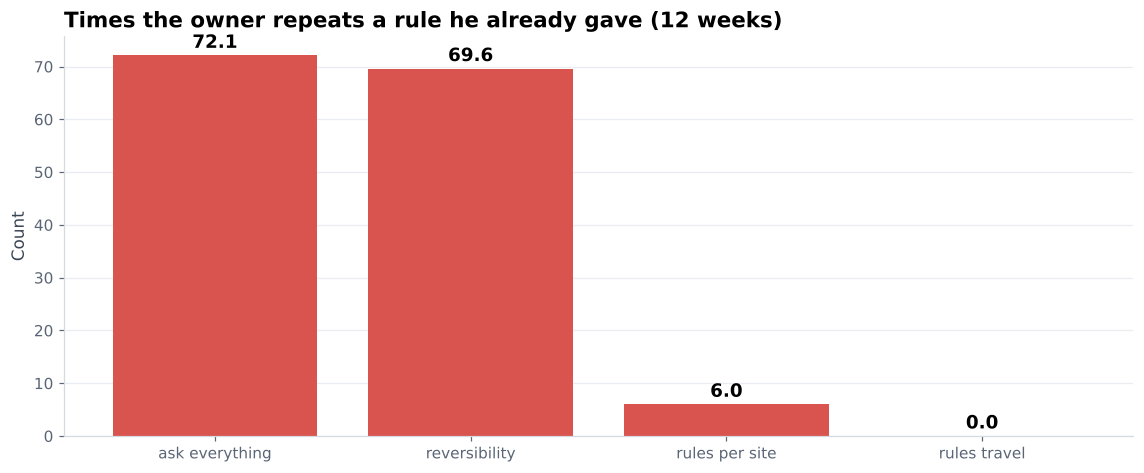

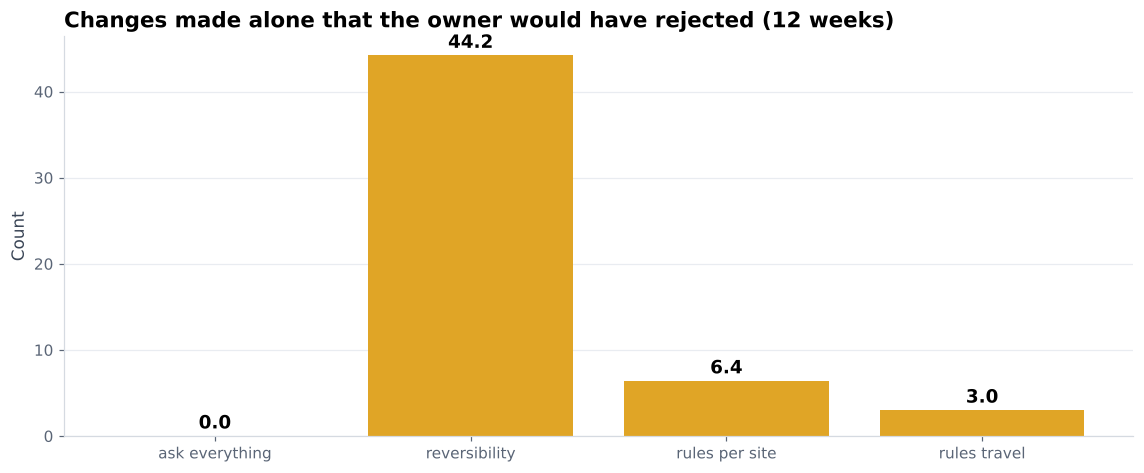

In [6]:
for col, title, c in [("re_specifications", "Times the owner repeats a rule he already gave (12 weeks)", PALETTE["coral"]),
                      ("changes_owner_would_reject", "Changes made alone that the owner would have rejected (12 weeks)", PALETTE["gold"])]:
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    bars = ax.bar(POL, res[col], color=c); ax.grid(axis="x", visible=False)
    for b_, v in zip(bars, res[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v + res[col].max() * 0.02, f"{v:.1f}", ha="center", fontsize=12, fontweight="bold")
    ax.set_title(title); ax.set_ylabel("Count")
    plt.tight_layout(); plt.show()

### What if the agent assumes every correction is global?

A tempting shortcut is to apply every correction everywhere. For brand rules this is wrong: the Tepeyac phrase rule would block legitimate changes on the finance site. The cell below counts those **wrongly blocked** changes.


In [7]:
def overgeneralize(weeks=12, seed=0):
    rng = np.random.default_rng(seed); known = set(); wrong_blocks = 0
    for w in range(weeks):
        for site, kind, touched in week_changes(rng):
            if any(r in known for r in touched) and not any(applies(r, site) for r in touched if r in known):
                wrong_blocks += 1
            for r in touched:
                if applies(r, site): known.add(r)
    return wrong_blocks
print(f"Treating every correction as global wrongly blocks about {np.mean([overgeneralize(seed=s) for s in range(20)]):.1f} "
      f"good changes in 12 weeks; asking once 'does this apply to all sites?' blocks none.")

Treating every correction as global wrongly blocks about 20.6 good changes in 12 weeks; asking once 'does this apply to all sites?' blocks none.


## 4. Findings

> **Key finding 1 (real data).** In its first week the SEO agent finished 7 of 10 internal documents by itself, but 3 of 5 staging changes and 2 of 3 production changes ended the week **waiting for the owner** (38% of everything it logged). The owner's approval, not the agent's work, set the pace.
>
> **Key finding 2.** Granting autonomy by **reversibility** (act alone on documents and staging, ask before code and production) cuts the owner's questions from 360 to about 126 in 12 weeks, but the agent then makes about 44 reversible changes the owner would reject, and the owner keeps repeating the same rules (about 70 times).
>
> **Key finding 3.** Corrections that **travel** (asked once whether they apply everywhere) bring errors down to about 3 and repeated rules to **zero**, against about 6 errors and 6 repeats when rules are learned site by site. Treating every correction as global instead would wrongly block about 21 good changes. The owner's profile has a **scope**: some rules are his everywhere, some belong to one brand, and the cheapest way to learn the scope is one question at the moment of the correction.

**Limitations:** a one-week real log (24 entries), simulated rules and frequencies, and an owner who always explains his rejections.

## 5. Thesis questions

1. Can an LLM agent infer a rule's scope (global, brand, page) from the wording of the correction and the context, and ask only when unsure?
2. Is reversibility enough, or does the owner's profile also weigh visibility (a reversible change seen by many clients may be worse than an irreversible internal one)?
3. How should rules learned by one agent (SEO) reach other agents (Press, GrabGo) that serve the same owner?

## References

1. Amodei, D., Olah, C., Steinhardt, J., Christiano, P., Schulman, J., & Mané, D. (2016). *Concrete Problems in AI Safety.* arXiv:1606.06565.
2. Krakovna, V., Orseau, L., Kumar, R., Martic, M., & Legg, S. (2019). *Penalizing side effects using stepwise relative reachability.* arXiv:1806.01186.
3. Bai, Y., et al. (2022). *Constitutional AI: Harmlessness from AI Feedback.* arXiv:2212.08073.
4. Aggarwal, P., Murahari, V., Rajpurohit, T., Kalyan, A., Narasimhan, K., & Deshpande, A. (2024). *GEO: Generative Engine Optimization.* KDD 2024. arXiv:2311.09735.
5. Mozannar, H., & Sontag, D. (2020). *Consistent Estimators for Learning to Defer to an Expert.* ICML 2020.
